# Weekly Loss Report
**Reporting week:** Oct 12-18, 2026  |  **Prepared:** Oct 20, 2026  |  **Scope:** Waste only (Breakage, Lost Items, Repeat Trip)

In [1]:
import sys
sys.path.insert(0, "../src")
from processor import *
from reusables import *
import numpy, pandas as pd, matplotlib
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Edit these each week -------------------------------------------------
WEEK_START  = "2026-10-12"
WEEK_LABEL  = "Week of Oct 12-18"
BASE_LABEL  = "Baseline"
WEEK_JOBS   = 36      # TODO: jobs completed in the reporting week (weekly_jobs)
BASE_JOBS   = 36      # TODO: jobs in the period the baseline covers
# ---------------------------------------------------------------------------

df, jobs, issues = prepare("../incident_log.db", start=WEEK_START)
df['kind'] = df['kind'].replace({"Lost Item": "Item Search"})
baseline, this_week = split_baseline(df)


def compare_weeks(baseline, current, base_jobs, cur_jobs, base_label, cur_label):
    """Baseline vs reporting week by kind, with a Total row and per-100-jobs rates."""
    b = cost_by(baseline).rename(columns={"events": "b_events", "total": "b_cost"})
    c = cost_by(current).rename(columns={"events": "c_events", "total": "c_cost"})
    t = b.join(c, how="outer").fillna(0)
    t.loc["Total"] = t.sum()
    t["b_p100"] = (t["b_cost"] / base_jobs * 100).round(2)
    t["c_p100"] = (t["c_cost"] / cur_jobs * 100).round(2)
    t["chg"] = (t["c_p100"] - t["b_p100"]).round(2)
    t["chg_pct"] = ((t["c_p100"] / t["b_p100"] - 1) * 100).round(0)
    t = t.replace([float("inf"), -float("inf")], float("nan"))
    t = t[["b_events", "b_cost", "b_p100", "c_events", "c_cost", "c_p100", "chg", "chg_pct"]]
    t.columns = pd.MultiIndex.from_tuples([
        (base_label, "Events"), (base_label, "Cost ($)"), (base_label, "Per 100 jobs ($)"),
        (cur_label, "Events"), (cur_label, "Cost ($)"), (cur_label, "Per 100 jobs ($)"),
        ("Change", "$ per 100 jobs"), ("Change", "%")])
    return t


table = compare_weeks(baseline, this_week, BASE_JOBS, WEEK_JOBS, BASE_LABEL, WEEK_LABEL)

## Summary

In [2]:
tot = table.loc["Total"]
cur  = tot[(WEEK_LABEL, "Per 100 jobs ($)")]
base = tot[(BASE_LABEL, "Per 100 jobs ($)")]
direction = "lower" if cur < base else "higher"
worst = table.drop("Total")[(WEEK_LABEL, "Cost ($)")].idxmax()

print(f"- {WEEK_LABEL}: {int(tot[(WEEK_LABEL, 'Events')])} waste events costing "
      f"${tot[(WEEK_LABEL, 'Cost ($)')]:,.2f} across {WEEK_JOBS} jobs.")
print(f"- Cost per 100 jobs was ${cur:,.2f}, {abs(cur - base) / base * 100:.0f}% "
      f"{direction} than the baseline (${base:,.2f}).")
print(f"- Largest cost driver this week: {worst}.")

- Week of Oct 12-18: 8 waste events costing $643.00 across 36 jobs.
- Cost per 100 jobs was $1,786.11, 62% lower than the baseline ($4,649.44).
- Largest cost driver this week: Item Search.


## Waste by type: baseline vs reporting week
Costs are totals; "per 100 jobs" adjusts for how busy each period was. A blank change means the type has no baseline entries.

In [3]:
table

Baseline                           Week of Oct 12-18           \
              Events Cost ($) Per 100 jobs ($)            Events Cost ($)   
kind                                                                        
Breakage        9.00   745.00         2,069.44              5.00   140.40   
Item Search     5.00   928.80         2,580.00              2.00   388.80   
Repeat Trip     0.00     0.00             0.00              1.00   113.80   
Total          14.00 1,673.80         4,649.44              8.00   643.00   

                                     Change         
            Per 100 jobs ($) $ per 100 jobs      %  
kind                                                
Breakage              390.00      -1,679.44 -81.00  
Item Search         1,080.00      -1,500.00 -58.00  
Repeat Trip           316.11         316.11    NaN  
Total               1,786.11      -2,863.33 -62.00

## Waste Event Details

In [6]:
cols = ["incident_date", "kind", "job_id", "item", "hours", "other_cost", "total_cost", "notes"]
cols = [c for c in cols if c in this_week.columns]       # skips any column your data doesn't have

details = (this_week[cols]
           .sort_values("total_cost", ascending=False)
           .rename(columns={"incident_date": "Date", "kind": "Type", "job_id": "Job",
                            "item": "Item", "hours": "Hours", "other_cost": "Other ($)",
                            "total_cost": "Total ($)", "notes": "Notes"}))

(details.style
    .hide(axis="index")
    .format({"Hours": "{:.1f}", "Other ($)": "${:,.2f}", "Total ($)": "${:,.2f}"}, na_rep="")
    .set_properties(subset=["Notes"], **{"white-space": "normal", "text-align": "left", "min-width": "200px"}))

Date,Type,Job,Item,Hours,Other ($),Total ($),Notes
2026-10-19 00:00:00,Item Search,,Other,16.0,,$345.60,
2026-10-19 00:00:00,Repeat Trip,GUTZEIT,Other,3.0,,$113.80,
2026-10-19 00:00:00,Item Search,,Other,2.0,,$43.20,
2026-10-19 00:00:00,Breakage,WATKINS,Furniture,2.0,$0.00,$43.20,
2026-10-19 00:00:00,Breakage,KING,Furniture,1.5,$0.00,$32.40,
2026-10-19 00:00:00,Breakage,CHERY,Personal items,1.0,$0.00,$21.60,
2026-10-19 00:00:00,Breakage,AMATO,Furniture,1.0,$0.00,$21.60,
2026-10-19 00:00:00,Breakage,AMATO,Art / decor,1.0,$0.00,$21.60,


## Charts

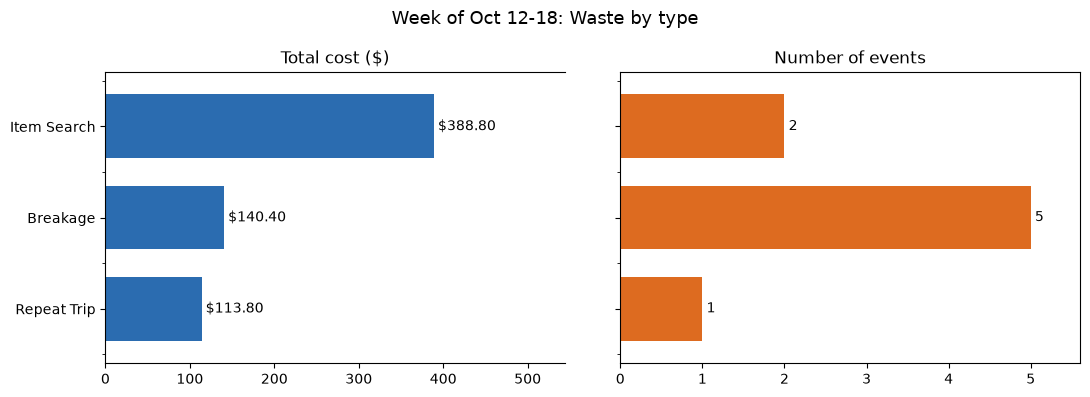

In [4]:
cost_events_chart(cost_by(this_week), title=f"{WEEK_LABEL}: Waste by type")

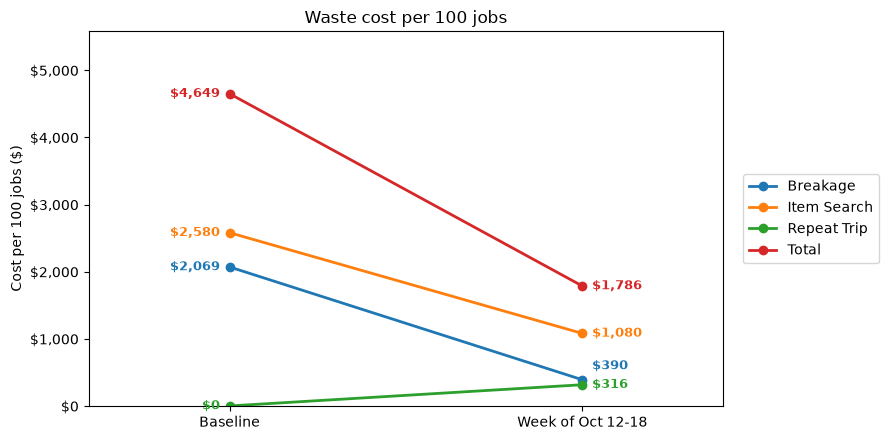

In [5]:
weekly_cost_chart(
    {BASE_LABEL: baseline, WEEK_LABEL: this_week},
    jobs={BASE_LABEL: BASE_JOBS, WEEK_LABEL: WEEK_JOBS},
    title="Waste cost per 100 jobs",
)

## Data notes
- Labor is costed at 21.60/hr. Mileage at 0.70/mile.
- The baseline is a historical import. It has no cause, crew or loss date, so it cannot be broken down further.
- The baseline search was re-costed at the current labor rate (712.50 to 928.80).
- Repeat Trip has no baseline entries because it was not tracked historically.
- One reporting week against an imported baseline shows direction, not a trend.